# Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('/Users/ccnlab/Development/dl4rl/')

import matplotlib.pyplot as plt
import seaborn as sns
import os
import utils.noisy_rl_utils as h
from typing import Hashable
from pandas.core.frame import DataFrame
import numpy as np
from scipy import special
import pandas as pd

In [4]:
# --- Experiment settings ---
experiment                 = 3
n_trials_per_block         = {0: 56, 1: 56, 2: 96, 3: 56}[experiment]
n_blocks                   = {0: 16, 1: 8, 2: 8, 3: 16}[experiment]
T                          = n_trials_per_block * n_blocks
n_agents_train             = 500
n_agents_test              = 0
n_agents                   = n_agents_train + n_agents_test
# --- Model settings ---
apply_rep_bias             = 1
apply_weber                = 1
apply_observational_noise  = 1
apply_counterfactual_learn = 1

model_name = "noisy_rl"
assert model_name in ["noisy_rl", "noiseless_rl"], "Invalid model name. Choose 'noisy_rl' or 'noiseless_rl'."
sim_fun = eval(f"h.simulate_{model_name}")
if model_name == "noisy_rl":
    has_epsilon = True

# Simulate

In [80]:
# --- Parameters ---
alpha_c = np.random.uniform(0.05, 0.7, size=n_agents)
alpha_u = (
    np.random.uniform(0.05, 0.5, size=n_agents)
    if apply_counterfactual_learn
    else np.zeros(n_agents)
)
beta = np.random.uniform(35.0, 35.0, size=n_agents)
epsilon = (
    np.random.uniform(0.01, 1.0, size=n_agents) if has_epsilon else np.zeros(n_agents)
)
rep_bias = (
    np.random.uniform(-0.25, 0.5, size=n_agents)
    if apply_rep_bias
    else np.zeros(n_agents)
)

alpha_c = np.random.uniform(0.57, 0.57, size=n_agents)
alpha_u = (
    np.random.uniform(0.59, 0.59, size=n_agents)
    if apply_counterfactual_learn
    else np.zeros(n_agents)
)
beta = np.random.uniform(35.0, 35.0, size=n_agents)
epsilon = (
    np.random.uniform(0.01, 1.0, size=n_agents) if has_epsilon else np.zeros(n_agents)
)
rep_bias = (
    np.random.uniform(-0.0, 0.0, size=n_agents)
    if apply_rep_bias
    else np.zeros(n_agents)
)
param_sets = np.column_stack((alpha_c, alpha_u, beta, epsilon, rep_bias))

In [81]:
max_workers = 4
sim_df = h.simulate_agents(
    model_name, param_sets, experiment, n_blocks, n_trials_per_block, len(param_sets), 
    apply_rep_bias, apply_weber, apply_observational_noise, apply_counterfactual_learn, 
    max_workers=max_workers
)

In [82]:
sim_df[['alpha_c']]

,alpha_c
0,0.57
1,0.57
2,0.57
3,0.57
4,0.57
...,...
447995,0.57
447996,0.57
447997,0.57
447998,0.57


In [9]:
sim_df.to_csv(f"../data/{model_name}/{n_agents}a_beta35_noisy_rl.csv")

# MI

In [63]:
param_keys = [ "epsilon"]
for param_key in param_keys:
    num_bins = 3
    beta_min = sim_df[param_key].min()
    beta_max = sim_df[param_key].max()
    beta_bins = np.linspace(beta_min, beta_max, num_bins + 1)
    sim_df[f"{param_key}_bin"] = pd.cut(
        sim_df[param_key], bins=beta_bins, labels=["Low", "Medium", "High"], include_lowest=True
    )

/var/folders/6y/khb9drcn0p373bwf72szrzvm0000gn/T/ipykernel_10035/1960172533.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sim_df.groupby(f"{param_key}_bin")


IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

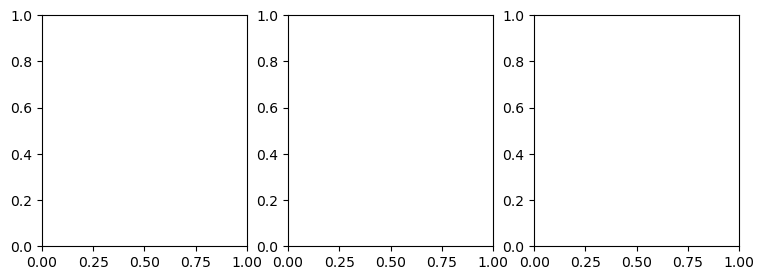

In [64]:
fig, axes = plt.subplots(nrows=len(param_keys), ncols=3, figsize=(3 * 3, 3*len(param_keys)))
for ri, param_key in enumerate(param_keys):
    for i, (bb, df) in enumerate[tuple[Hashable, DataFrame]](
        sim_df.groupby(f"{param_key}_bin")
    ):
        _, ax, plot_df = h.plot_mi_vs_params(df, "epsilon", fig=fig, ax=axes[ri, i])
        ax.set_title(f"{param_key}:{bb}")

fig.tight_layout()

In [83]:
# Calculate non-greedy choice proportion per block based on 'action' and 'greedy_choice' in sampled_data
param = 'epsilon_bin'

free = sim_df[(sim_df["free_choice"] == 1) & (sim_df["trial"] > 0)]
non_greedy_df = (
    free.assign(non_greedy=1.0 - free["greedy_choice"])
    .groupby(["subj_code", 'block'], as_index=False)["non_greedy"]
    .mean()
    .rename(columns={"non_greedy": "prop_non_greedy"})
)

mi_df = (
    sim_df.groupby(["subj_code", 'block'])
    .apply(h.get_mi_bits)
    .reset_index()
    .rename(columns={0: "mutual_info"})
)

/var/folders/6y/khb9drcn0p373bwf72szrzvm0000gn/T/ipykernel_10035/2734117169.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(h.get_mi_bits)


<Axes: xlabel='prop_non_greedy', ylabel='mutual_info'>

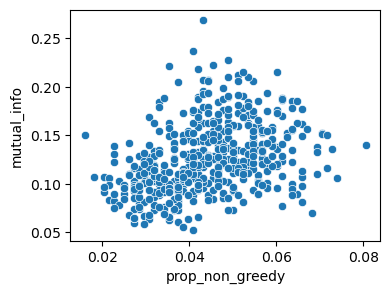

In [90]:
d = pd.merge(non_greedy_df, mi_df, on=['subj_code', 'block'], how='left')
d = d.groupby('subj_code').agg({'mutual_info': 'mean', 'prop_non_greedy': 'mean'})
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(4 * 1, 3*1))
sns.scatterplot(
    data=d,
    x='prop_non_greedy',
    y="mutual_info",
    #scatter_kws={"s": 10},
    #label=rf"$\{param}$" if param != "rep_bias" else r"$\xi$",
    ax=axes,
)

# Action selection vs parameters

/var/folders/6y/khb9drcn0p373bwf72szrzvm0000gn/T/ipykernel_52140/2034667557.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sim_df.groupby(f"{param_key}_bin")


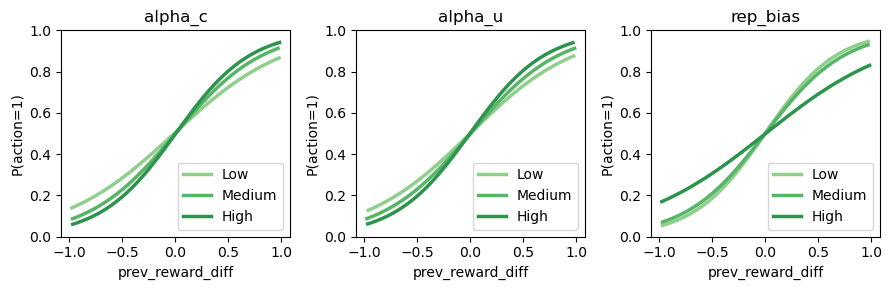

In [46]:
xvar = "prev_reward_diff"
yvar = "action"
palette = sns.color_palette("Greens")[2:]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(3 * 3, 3))
for ri, param_key in enumerate(param_keys):
    ax = axes[ri]
    for i, (bb, df) in enumerate[tuple[Hashable, DataFrame]](
        sim_df.groupby(f"{param_key}_bin")
    ):
        # We use a label here so the legend can find the "artist"
        ax = sns.regplot(
            data=df,
            x=xvar,
            y=yvar,
            logistic=True,
            scatter=False,
            ci=None,
            line_kws={"color": palette[i], "linewidth": 2.5},
            ax=ax,
            label=bb,
        )
    ax.legend(title="", loc="lower right")
    ax.set_title(f"{param_key}")
    ax.set_ylabel("P(action=1)")
    ax.set_ylim(0, 1)

fig.tight_layout()

In [62]:
import pandas as pd
from pandas._config.config import register_option, is_bool

try:
    pd.get_option("mode.use_inf_as_null")
except pd.errors.OptionError:
    register_option("mode.use_inf_as_null", False, validator=is_bool)

/Users/ccnlab/miniconda3/envs/dl4rl-k3/lib/python3.12/site-packages/seaborn/_core.py:989: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = data.groupby(
/Users/ccnlab/miniconda3/envs/dl4rl-k3/lib/python3.12/site-packages/seaborn/_core.py:1007: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Users/ccnlab/miniconda3/envs/dl4rl-k3/lib/python3.12/site-packages/seaborn/_core.py:1007: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grou

(<Figure size 900x300 with 3 Axes>,
 array([<Axes: title={'center': 'alpha_c_bin= Low'}, xlabel='Trials since reward crossover', ylabel='P(choose new optimal)'>,
        <Axes: title={'center': 'alpha_c_bin= Medium'}, xlabel='Trials since reward crossover', ylabel='optimal_choice'>,
        <Axes: title={'center': 'alpha_c_bin= High'}, xlabel='Trials since reward crossover', ylabel='optimal_choice'>],
       dtype=object))

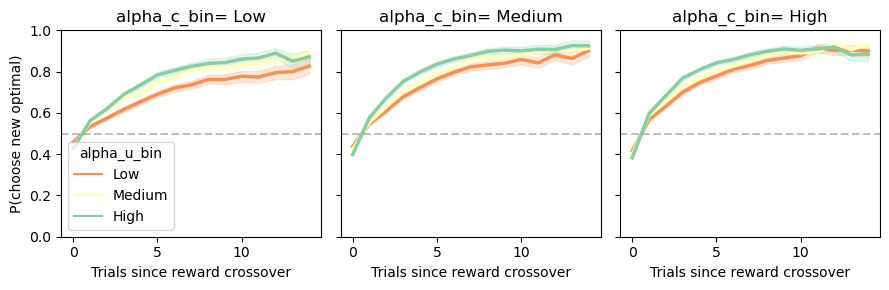

In [65]:
h.plot_switch_adaptation(sim_df, 'alpha_c_bin', 'alpha_u_bin')